### Passing Difficluty
The idea here is to split the passes into categories dependent on their xpass value, i.e. easy, moderate and difficult passes. Evaluating player's PAx at each of these different difficulties will provide better insight into their passing abilities rather than one overall PAx for all pass types.

In [1]:
# ------------------------------------
# 1. Import the data
# -------------------------------------

from pathlib import Path
import pandas as pd

xpass_df = pd.read_csv(Path.cwd().parent / "data/cleaned/all_xpass_25-27.csv")

In [11]:
# -----------------------------------------------------
# 2. Split the passing data into bins by difficulty
# -----------------------------------------------------
xpass_df["difficulty"] = pd.cut(xpass_df["xPass"],
                                bins = [0,0.6,0.85,1.0],
                                labels = ["Difficult",
                                          "Moderate",
                                          "Easy"],
                                include_lowest = True)

# Check the distribution of passes
difficulty_distribution = (xpass_df.groupby("difficulty", observed = False)
                                   .agg(passes = ("xPass", "sum"),
                                        avg_xpass = ("xPass", "mean")))

difficulty_distribution["share"] = difficulty_distribution["passes"] / difficulty_distribution["passes"].sum() * 100

display(difficulty_distribution)

,passes,avg_xpass,share
difficulty,,,
Difficult,1.337576e+05,0.310341,7.543211
Moderate,2.095496e+05,0.752517,11.817469
Easy,1.429912e+06,0.966208,80.639320


In [51]:
# ------------------------------------
# 3. Calculate player stats by difficulty
# -------------------------------------

player_difficulty = (
    xpass_df
    .groupby(
        ["player_id", "league", "difficulty"],
        observed=True
    )
    .agg(
        player = ("player", "first"),
        attempted_passes=("xPass", "size"),
        completed_passes=("outcome", "sum"),
        avg_xPass=("xPass", "mean"),
        total_PAx=("PAx", "sum")
    )
    .reset_index()
)

player_difficulty["passing_accuracy"] = (
    player_difficulty["completed_passes"] /
    player_difficulty["attempted_passes"]
) * 100 

player_difficulty["PAx_per_100"] = (
    player_difficulty["total_PAx"] /
    player_difficulty["attempted_passes"] * 100
)

In [53]:
# ------------------------------------
# 4. Check best and worst performers
# -------------------------------------

# Minimum 100 attempts in the relevant difficulty band
qualified_players = player_difficulty[
    player_difficulty["attempted_passes"] >= 100
].copy()

for difficulty in player_difficulty["difficulty"].cat.categories:

    subset = qualified_players[
        qualified_players["difficulty"] == difficulty
    ]

    print(f"\n{difficulty}")

    print("\nBest performers:")
    display(
        subset.nlargest(10, "PAx_per_100")[
            ["player", "attempted_passes", "passing_accuracy",
             "avg_xPass", "PAx_per_100"]
        ]
    )

    print("\nWorst performers:")
    display(
        subset.nsmallest(10, "PAx_per_100")[
            ["player", "attempted_passes", "passing_accuracy",
             "avg_xPass", "PAx_per_100"]
        ]
    )


Difficult

Best performers:


,player,attempted_passes,passing_accuracy,avg_xPass,PAx_per_100
1800,Frenkie de Jong,111,59.459459,0.385799,20.879512
4917,Karl Hein,182,42.857143,0.289175,13.939679
844,Piotr Zielinski,164,46.341463,0.327026,13.638852
8793,Nathaniel Adjei,107,46.728972,0.345011,12.227878
3987,Egil Selvik,160,39.375000,0.271585,12.216545
4335,Sebastian Walukiewicz,283,45.229682,0.334971,11.732575
9038,Noahkai Banks,142,47.183099,0.355884,11.594737
838,Alessio Romagnoli,179,49.162011,0.380993,11.062703
2219,Radoslaw Majecki,160,41.875000,0.310861,10.788871
315,Isco,102,44.117647,0.333495,10.768158



Worst performers:


,player,attempted_passes,passing_accuracy,avg_xPass,PAx_per_100
513,Maxime Dupé,100,18.000000,0.327180,-14.718043
3105,Nico González,141,17.021277,0.293096,-12.288285
2544,Ismaïla Sarr,134,18.656716,0.291794,-10.522706
1335,Tomás Soucek,181,19.889503,0.302265,-10.337025
7104,Kauã Santos,186,18.817204,0.290090,-10.191749
5863,Jobe Bellingham,137,24.087591,0.342239,-10.136356
1947,Habib Diallo,106,19.811321,0.299467,-10.135367
5537,Alex Scott,317,18.611987,0.286434,-10.031416
3204,Martín Payero,133,19.548872,0.295071,-9.958236
3574,Gorka Guruzeta,163,22.699387,0.325375,-9.838121



Moderate

Best performers:


,player,attempted_passes,passing_accuracy,avg_xPass,PAx_per_100
5910,Joan García,107,92.523364,0.744545,18.068822
1765,David Raya,122,90.983607,0.736871,17.296540
27,Manuel Neuer,111,89.189189,0.737648,15.424353
2142,Ezri Konsa,139,90.647482,0.771287,13.518752
2217,Rodri,155,89.677419,0.767468,12.930579
5611,Pablo Ramón,102,90.196078,0.773165,12.879541
1122,Jonathan Tah,211,89.573460,0.768976,12.675839
9121,Marc Bernal,116,88.793103,0.766235,12.169575
1648,Jean Butez,142,85.211268,0.735318,11.679473
3474,William Saliba,118,85.593220,0.740604,11.532850


... (2 outputs left out)


Easy

Best performers:


,player,attempted_passes,passing_accuracy,avg_xPass,PAx_per_100
2734,Facundo Medina,447,100.000000,0.958476,4.152378
7967,Mats Rots,215,100.000000,0.959191,4.080918
3603,Leonardo Balerdi,153,99.346405,0.953785,3.967955
7382,Aurèle Amenda,100,100.000000,0.960533,3.946674
9268,Kerim Alajbegovic,138,99.275362,0.953403,3.935103
4304,Joey Veerman,238,99.159664,0.954185,3.741165
9537,Fabio Gruber,231,99.567100,0.958982,3.668869
3143,Ibrahima Konaté,448,99.553571,0.960145,3.539116
440,Mateo Kovacic,199,99.497487,0.959772,3.520244
2110,Christopher Nkunku,117,99.145299,0.956352,3.510058



Worst performers:


,player,attempted_passes,passing_accuracy,avg_xPass,PAx_per_100
1293,Dominic Calvert-Lewin,269,82.156134,0.942437,-12.087565
46,Olivier Giroud,220,83.181818,0.943333,-11.151472
8819,Carlos Espí,109,83.486239,0.943452,-10.859005
353,Michael Gregoritsch,125,83.200000,0.939474,-10.747423
1808,Toni Martínez,333,84.684685,0.952349,-10.550228
681,Raúl Jiménez,282,85.106383,0.950033,-9.896909
5387,Igor Matanovic,221,84.615385,0.944008,-9.785409
2377,Richarlison,167,84.431138,0.936815,-9.250343
192,Youssef El-Arabi,144,86.111111,0.952569,-9.145832
404,Álvaro Morata,161,86.335404,0.954807,-9.145280


In [55]:
# --------------------------------------------------
# 5. Calculate overall player statistics
# --------------------------------------------------
player_overall = (
    xpass_df
    .groupby(["player_id", "league"], observed=True)
    .agg(
        player=("player", "first"),
        attempted_passes=("xPass", "size"),
        completed_passes = ("outcome", "sum"),
        avg_xPass=("xPass", "mean"),
        total_PAx=("PAx", "sum")
    )
    .reset_index()
)

player_overall["PAx_per_100"] = (
    player_overall["total_PAx"] /
    player_overall["attempted_passes"] * 100
)

player_overall["passing_accuracy"] = (
    player_overall["completed_passes"] /
    player_overall["attempted_passes"]
) * 100

player_overall["difficulty"] = "Overall"

In [43]:
# --------------------------------------------------
# 6. Combine overall and difficulty statistics
# --------------------------------------------------

player_comparison = pd.concat(
    [player_overall, player_difficulty],
    ignore_index=True
)

display(player_comparison[player_comparison["player"] == "Santi Cazorla"])

,player_id,league,player,attempted_passes,completed_passes,avg_xPass,total_PAx,PAx_per_100,passing_accuracy,difficulty
2,4522.0,ESP-La Liga,Santi Cazorla,617,488,0.787020,2.408545,0.390364,79.092382,Overall
3556,4522.0,ESP-La Liga,Santi Cazorla,143,45,0.311074,0.516459,0.361160,31.468531,Difficult
3557,4522.0,ESP-La Liga,Santi Cazorla,74,57,0.760803,0.700541,0.946678,77.027027,Moderate
3558,4522.0,ESP-La Liga,Santi Cazorla,400,386,0.962021,1.191544,0.297886,96.500000,Easy


In [57]:
# --------------------------------------------------
# 7. Calculate attempt share
# --------------------------------------------------

overall_attempts = (
    player_overall[
        ["player_id", "league", "attempted_passes"]
    ]
    .rename(
        columns={"attempted_passes": "total_attempts"}
    )
)

player_comparison = player_comparison.merge(
    overall_attempts,
    on=["player_id", "league"],
    how="left"
)

player_comparison["attempt_share"] = (
    player_comparison["attempted_passes"] /
    player_comparison["total_attempts"]
) * 100

In [61]:
display(
    player_comparison[
        player_comparison["player"] == "Kevin De Bruyne"
    ][
        [
            "player",
            "league",
            "difficulty",
            "attempted_passes",
            "attempt_share",
            "passing_accuracy",
            "avg_xPass",
            "PAx_per_100",
        ]
    ].sort_values("difficulty")
)

,player,league,difficulty,attempted_passes,attempt_share,passing_accuracy,avg_xPass,PAx_per_100
3768,Kevin De Bruyne,ITA-Serie A,Difficult,241,18.828125,25.311203,0.279902,-2.678999
3770,Kevin De Bruyne,ITA-Serie A,Easy,858,67.031250,96.969697,0.963125,0.657203
3769,Kevin De Bruyne,ITA-Serie A,Moderate,181,14.140625,63.535912,0.748948,-11.358935
73,Kevin De Bruyne,ITA-Serie A,Overall,1280,100.000000,78.750000,0.804201,-1.670098


In [207]:

import pandas as pd
import numpy as np
import plotly.graph_objects as go
from plotly.subplots import make_subplots


def plot_player_pax_comparison(player_one, player_two):

    # --------------------------------------------------
    # 1. Settings
    # --------------------------------------------------

    difficulty_bands = [
        "Difficult",
        "Moderate",
        "Easy"]

    difficulty_labels = [
    "Difficult Passes<br>(xP ≤ 0.60)",
    "Moderate Passes<br>(0.60 < xP ≤ 0.85)",
    "Easy Passes<br>(xP > 0.85)"
]

    player_colours = {
        player_one: "#5B9CD9",
        player_two: "#5B5ED9"
    }

    # --------------------------------------------------
    # 2. Find each player
    # --------------------------------------------------

    def get_player_data(player_name):

        player_data = player_comparison[
            player_comparison["player"].str.strip().str.casefold()
            == player_name.strip().casefold()
        ].copy()

        overall = player_data[
            player_data["difficulty"] == "Overall"
        ]

        if overall.empty:
            raise ValueError(
                f"No records found for {player_name}."
            )

        if len(overall) > 1:
            leagues = overall["league"].tolist()

            raise ValueError(
                f"{player_name} appears in multiple leagues: "
                f"{leagues}. Please use a unique player name."
            )

        return player_data, overall.iloc[0]

    players = {}

    for name in [player_one, player_two]:

        data, overall = get_player_data(name)

        players[name] = {
            "data": data,
            "overall": overall
        }

    # --------------------------------------------------
    # 3. Create subplots
    # --------------------------------------------------

    fig = make_subplots(
        rows=2,
        cols=1,
        shared_xaxes=False,
        vertical_spacing=0.10,
        row_heights=[0.28, 0.72],
        subplot_titles=[
            "Overall Passing Performance",
            "Passing Performance by Pass Difficulty"
        ]
    )

    # --------------------------------------------------
    # 4. Overall PAx comparison
    # --------------------------------------------------

    for name in [player_one, player_two]:

        overall = players[name]["overall"]

        customdata = [[
            overall["attempted_passes"],
            overall["passing_accuracy"],
            overall["avg_xPass"],
            overall["league"]
        ]]

        fig.add_trace(
            go.Bar(
                x=[overall["PAx_per_100"]],
                y=[name],
                orientation="h",
                name=name,
                marker_color=player_colours[name],
                customdata=customdata,
                hovertemplate=(
                    "<b>%{y}</b><br>"
                    "PAx per 100: %{x:.2f}<br>"
                    "Attempted Passes: %{customdata[0]:,.0f}<br>"
                    "Passing Accuracy: %{customdata[1]:.1f}%<br>"
                    "Average xPass: %{customdata[2]:.3f}<br>"
                    "<extra></extra>"
                ),
                showlegend=False
            ),
            row=1,
            col=1
        )

    # --------------------------------------------------
    # 5. Difficulty contribution comparison
    # --------------------------------------------------

    for name in [player_one, player_two]:

        data = players[name]["data"]

        difficulty_data = (
            data[data["difficulty"].isin(difficulty_bands)]
            .set_index("difficulty")
            .reindex(difficulty_bands)
        )

        # Missing bands mean zero attempts and contribution
        difficulty_data["attempted_passes"] = (
            difficulty_data["attempted_passes"].fillna(0)
        )

        for column in [
            "PAx_per_100",
            "avg_xPass",
            "attempted_passes",
            "attempt_share",
            "passing_accuracy"]:
            
            difficulty_data[column] = (
                difficulty_data[column].fillna(0)
            )

        customdata = np.column_stack([
            difficulty_data["PAx_per_100"],
            difficulty_data["attempted_passes"],
            difficulty_data["attempt_share"],
            difficulty_data["passing_accuracy"],
            difficulty_data["avg_xPass"],
            difficulty_data.index.to_numpy()],
)

        fig.add_trace(
            go.Bar(
                x=difficulty_data["PAx_per_100"],
                y=difficulty_bands,
                orientation="h",
                name=name,
                marker_color=player_colours[name],
                customdata=customdata,
                hovertemplate=(
                    "<b>%{customdata[5]} Passes</b><br>"
                    "PAx per 100: %{x:.2f}<br>"
                    "Attempted Passes: %{customdata[1]:.0f}<br>"
                    "Attempt Share: %{customdata[2]:.2f}%<br>"
                    "Passing Accuracy: %{customdata[3]:.2f}%<br>"
                    "Average xPass: %{customdata[4]:.2f}<br>"
                    "<extra></extra>"
                ),
                showlegend=False
            ),
            row=2,
            col=1
        )

    # --------------------------------------------------
    # 6. Layout and styling
    # --------------------------------------------------

    fig.update_layout(
        title=dict(
            text=f"{player_two} vs {player_one} Passing Performance",
            x=0.52,
            xanchor="center",
            font = dict(size = 20)
        ),
        height = None,
        width = None,
        autosize = True,
        template="plotly_dark",
        paper_bgcolor="#404040",
        plot_bgcolor="#404040",
        font=dict(
            family="DIN Alternate, Arial",
            color="#CCCCCC",
            size=12
        ),
        showlegend = False,
        barmode="group",
        bargap=0.35,
        bargroupgap=0.15,
        margin=dict(
            l=50,
            r=50,
            t=110,
            b=70
        ),
        hoverlabel=dict(
            bgcolor="#303030",
            font_color="#FFFFFF"
        )
    )

    # Zero reference lines
    fig.update_xaxes(
        zeroline=True,
        zerolinewidth=1.5,
        zerolinecolor="#CCCCCC",
        showgrid=False,
        showline=True,
        linecolor="#888888"
    )

    fig.update_yaxes(
        showgrid=False,
        showline=False,
        row=1,
        col=1,
    )

    fig.update_yaxes(
        tickmode="array",
        tickvals=difficulty_bands,
        ticktext=difficulty_labels,
        row=2,
        col=1
    )

    fig.update_xaxes(
        title_text="PAx per 100 passes",
        row=1,
        col=1
    )

    fig.update_xaxes(
        title_text="PAx per 100 Passes",
        row=2,
        col=1
    )

    fig.show()

    return fig


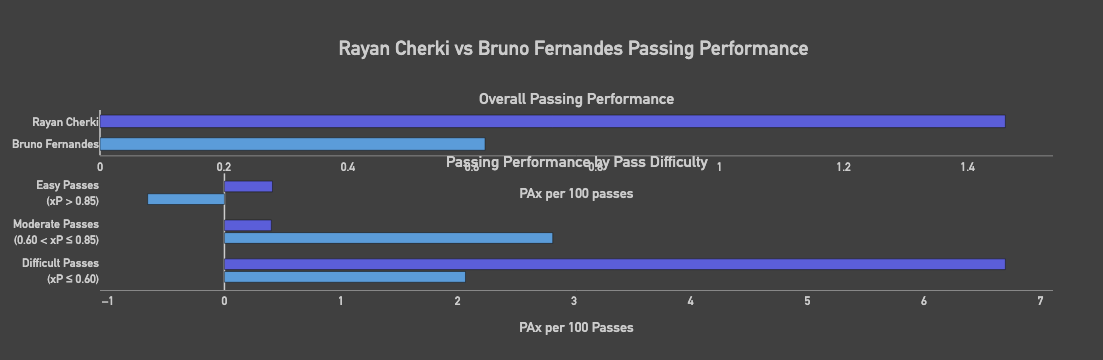

In [241]:
fig = plot_player_pax_comparison(
    "Bruno Fernandes",
    "Rayan Cherki"
)

fig.write_html(Path.cwd().parent / "figures/players/player-comparison.html",
               config = {"responsive" : True,
                        "displayModeBar" : False})